# Active learning por incerteza

Este exemplo usa dados sintéticos e rótulos conhecidos para simular um anotador. Começamos com poucas amostras rotuladas, escolhemos casos do pool com probabilidade próxima de 0,5 e revelamos seus rótulos. Em uma aplicação real, uma pessoa anotaria os casos selecionados.

O teste fica separado desde o início. Suas métricas apenas relatam o experimento e não participam da seleção das amostras.

In [1]:
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "module_olist").is_dir())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from sklearn.datasets import make_classification
from module_olist.active_learning import run_active_learning
import matplotlib.pyplot as plt

X, y = make_classification(n_samples=600, n_features=10, n_informative=5,
                           weights=[0.75, 0.25], random_state=42)
result = run_active_learning(X, y, initial_size=30, batch_size=15, rounds=6)
display(result.history)


2026-10-27 08:46:00.492 | INFO     | module_olist.config:<module>:11 - PROJ_ROOT path is: /Users/ryanbernardo/Documents/Faculdade/MachineLearning/ML_projeto_SENAI/olist


,round,n_labeled,pool_size,test_accuracy,test_roc_auc
0,0,30,420,0.846667,0.830827
1,1,45,405,0.893333,0.852679
2,2,60,390,0.900000,0.875470
3,3,75,375,0.900000,0.887218
4,4,90,360,0.893333,0.883694
5,5,105,345,0.906667,0.884633
6,6,120,330,0.906667,0.884164


## Custo de anotação e desempenho

Cada rodada acrescenta no máximo 15 rótulos. A melhora não é garantida: depende do modelo, dos dados e da estratégia. Este exemplo demonstra o ciclo e não compara sua eficiência com amostragem aleatória.

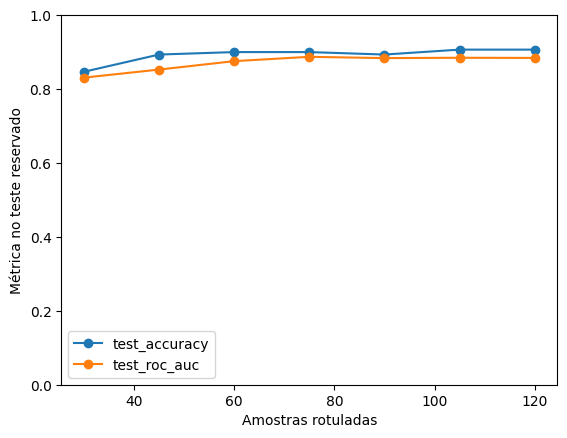

In [2]:
ax = result.history.plot(x="n_labeled", y=["test_accuracy", "test_roc_auc"], marker="o")
ax.set_xlabel("Amostras rotuladas")
ax.set_ylabel("Métrica no teste reservado")
ax.set_ylim(0, 1)
plt.show()


## Conferência da separação dos dados

In [3]:
queried = [i for batch in result.queried_indices for i in batch]
labeled = result.initial_indices + queried
assert len(labeled) == len(set(labeled))
assert set(labeled).isdisjoint(result.test_indices)
print("Rótulos iniciais:", len(result.initial_indices))
print("Consultas ao anotador:", len(queried))
print("Teste reservado:", len(result.test_indices))


Rótulos iniciais: 30
Consultas ao anotador: 90
Teste reservado: 150
